In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin

class PrevalenceFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.05):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.keep_columns_ = X.columns[(X > 0).mean(axis=0) >= self.threshold]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.loc[:, self.keep_columns_]

In [5]:
from sklearn.feature_selection import VarianceThreshold

In [1]:
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

NameError: name 'pd' is not defined

In [9]:
# Load metagenomic species abundance table
species = pd.read_csv("data/species.tsv.zip", sep="\t")

# Load metadata
metadata = pd.read_csv("data/metadata.tsv", sep="\t")

print("Species shape:", species.shape)
print("Metadata shape:", metadata.shape)

Species shape: (347, 57703)
Metadata shape: (347, 15)


In [4]:
species.head()

,Sample,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965,d__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795,d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibacteraceae;g__JAAYPI01;s__JAAYPI01 sp012519885,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Flavobacteriaceae;g__Flavobacterium;s__Flavobacterium sp017989775,...,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1;s__LC3-1 sp016781735,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Sphingomonadales;f__Sphingomonadaceae;g__Sphingorhabdus_B;s__Sphingorhabdus_B sp012032285,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Pseudomonadaceae;g__Pseudomonas_E;s__Pseudomonas_E sp900187445,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902591535,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales_A;f__Enterobacteriaceae_A;g__GCA-012562765;s__GCA-012562765 sp012569925,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902631135,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Puniceispirillales;f__Puniceispirillaceae;g__UBA5951;s__UBA5951 sp902625725,d__Bacteria;p__Verrucomicrobiota;c__Kiritimatiellae;o__SS1-B-03-39;f__UBA6053;g__PXAS01;s__PXAS01 sp003565815,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451;s__UBA7451 sp002457275,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__CACIJG01;s__CACIJG01 sp902580265
0,10021,0.000181,0.0,0.0,0.000006,0.0,0.000002,1.301684e-06,3.154081e-06,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
1,10023,0.000499,0.0,0.0,0.000008,0.0,0.000002,2.213688e-06,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
2,10025,0.000018,0.0,0.0,0.000005,0.0,0.000002,2.976180e-07,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
3,10029,0.000051,0.0,0.0,0.000003,0.0,0.000005,4.691933e-07,2.580563e-07,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
4,10031,0.000011,0.0,0.0,0.000000,0.0,0.000002,5.167816e-07,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0


In [5]:
metadata.head()

,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
0,YACHIDA_CRC_2019,10021,10021,Stage_I_II,57,Years,Male,26.880952,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,I,130,993.0,Left colon,False
1,YACHIDA_CRC_2019,10023,10023,Healthy,65,Years,Male,26.562500,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,660,0.0,-,False
2,YACHIDA_CRC_2019,10025,10025,Healthy,40,Years,Male,25.000000,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,400,993.0,-,True
3,YACHIDA_CRC_2019,10029,10029,Healthy,67,Years,Female,20.173253,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.0,-,False
4,YACHIDA_CRC_2019,10031,10031,Healthy,77,Years,Male,24.464602,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,300,813.0,-,False


In [6]:
print(species.columns[:10])   # first 10 columns
print(metadata.columns)

Index(['Sample',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965',
       'd__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795',
       'd__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibactera

In [10]:
# Merge species table with metadata
data = species.merge(metadata, on="Sample", how="inner")

print(data.shape)

(347, 57717)


In [11]:
data["Study.Group"].value_counts()

Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
HS               30
Stage_0          27
Name: count, dtype: int64

In [12]:
data = data[
    data["Study.Group"].isin(["Healthy", "Stage_III_IV"])
].copy()

print(data["Study.Group"].value_counts())

Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64


In [13]:
data["Label"] = (
    data["Study.Group"] == "Stage_III_IV"
).astype(int)

data[["Study.Group", "Label"]].head()

,Study.Group,Label
1,Healthy,0
2,Healthy,0
3,Healthy,0
4,Healthy,0
7,Healthy,0


In [14]:
feature_cols = species.columns.drop("Sample")

X = data[feature_cols].copy()
y = data["Label"].copy()

print("X shape before filtering:", X.shape)
print("y shape:", y.shape)
print(y.value_counts())

X shape before filtering: (181, 57702)
y shape: (181,)
Label
0    127
1     54
Name: count, dtype: int64


In [15]:
prevalence = (X > 0).mean(axis=0)

keep_features = prevalence[prevalence >= 0.05].index

X_filtered = X[keep_features].copy()

print("X shape after prevalence filtering:", X_filtered.shape)

X shape after prevalence filtering: (181, 24519)


In [ ]:
# prevalence = (X > 0).mean(axis=0)

# keep_features_10 = prevalence[prevalence >= 0.10].index

# X_filtered_10 = X[keep_features_10]

# print(X_filtered_10.shape)

(347, 17692)


In [17]:
prevalence = (X > 0).mean(axis=0)

keep_features_15 = prevalence[prevalence >= 0.15].index

X_filtered_15 = X[keep_features_15]

print(X_filtered_15.shape)

(181, 13882)


In [18]:
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(threshold=0)

X_var = vt.fit_transform(X_filtered_15)

selected_features = X_filtered_15.columns[vt.get_support()]

X_var = pd.DataFrame(
    X_var,
    columns=selected_features,
    index=X_filtered_15.index
)

print("Shape after removing zero-variance features:", X_var.shape)

Shape after removing zero-variance features: (181, 13882)


In [ ]:
#!pip install xgboost

In [16]:
import xgboost
print(xgboost.__version__)

3.3.0


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBClassifier
import numpy as np

xgb_species_pipe = Pipeline([
    ("prevalence", PrevalenceFilter(threshold=0.15)),
    ("variance", VarianceThreshold(threshold=0)),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("xgb", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

Species XGBoost ROC-AUC: 0.816


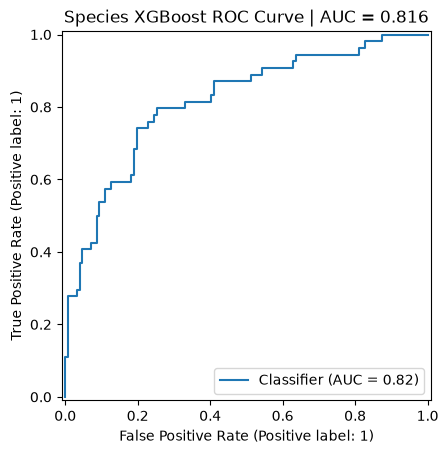

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, RocCurveDisplay

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

y_species_pred_proba = cross_val_predict(
    xgb_species_pipe, X, y, cv=cv,
    method="predict_proba", n_jobs=-1
)[:, 1]

auc_species = roc_auc_score(y, y_species_pred_proba)

print("Species XGBoost ROC-AUC:", round(auc_species, 3))

RocCurveDisplay.from_predictions(y, y_species_pred_proba)
plt.title(f"Species XGBoost ROC Curve | AUC = {auc_species:.3f}")
plt.show()

ROC-AUC = 0.831 indicates good discrimination. The model separates Healthy and Stage III/IV substantially better than random (0.5), although there is still room for improvement.
The curve rises steeply at low false-positive rates, which is encouraging—it means the model identifies many true positives without too many false positives initially.
There isn't much evidence of severe overfitting from this figure alone, but we still need cross-validation statistics (mean ± SD) and eventually compare with Random Forest and LASSO.

In [14]:
from sklearn.model_selection import cross_val_score

species_auc_scores = cross_val_score(
    xgb_species_pipe,
    X_var,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Species fold AUCs:", np.round(species_auc_scores, 3))
print("Species mean ROC-AUC:", round(species_auc_scores.mean(), 3))
print("Species SD ROC-AUC:", round(species_auc_scores.std(), 3))

Species fold AUCs: [0.936 0.969 0.969 0.769 0.662 0.892 1.    0.806 0.708 0.75 ]
Species mean ROC-AUC: 0.846
Species SD ROC-AUC: 0.116


Baseline XGBoost achieved a pooled 10-fold CV ROC-AUC of 0.831.
Across folds, performance was summarized as mean ROC-AUC ± SD.
All preprocessing used for modelling was included in the pipeline to avoid data leakage.

In [22]:
# from sklearn.model_selection import GridSearchCV, StratifiedKFold
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import FunctionTransformer
# from xgboost import XGBClassifier

# tuning_pipe = Pipeline([
#     ("log", FunctionTransformer(np.log1p, validate=False)),
#     ("xgb", XGBClassifier(
#         objective="binary:logistic",
#         eval_metric="logloss",
#         random_state=42,
#         n_jobs=2
#     ))
# ])

# param_grid = {
#     "xgb__n_estimators": [100, 300],
#     "xgb__max_depth": [2, 3],
#     "xgb__learning_rate": [0.05, 0.1],
#     "xgb__subsample": [0.8],
#     "xgb__colsample_bytree": [0.5, 0.8]
# }

# cv_tune = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# species_grid = GridSearchCV(
#     tuning_pipe,
#     param_grid,
#     scoring="roc_auc",
#     cv=cv_tune,
#     n_jobs=1,
#     verbose=2
# )

# species_grid.fit(X_var, y)

# print("Best species params:", species_grid.best_params_)
# print("Best species CV ROC-AUC:", round(species_grid.best_score_, 3))

# Genera :XGBoost

In [22]:
genera = pd.read_csv("data/genera.tsv", sep="\t")

print(genera.shape)
genera.head()

(347, 11943)


,Sample,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Monoglobales;f__Firm-18;g__UBA1775,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Peptostreptococcales;f__Acidaminobacteraceae;g__Fusibacter_A,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__Oceaniglobus,d__Bacteria;p__Myxococcota;c__Polyangia;o__Polyangiales;f__SG8-38;g__JAAYBZ01,d__Bacteria;p__Patescibacteria;c__Paceibacteria;o__UBA6257;f__02-FULL-45-10c;g__JACROC01,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__CAG-272;g__Flemingibacterium,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__F0428,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnoanaerobaculum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Carnobacteriaceae;g__Carnobacterium_A,...,d__Bacteria;p__Patescibacteria;c__Kazan-3B-28;o__Kazan-3B-28;f__UBA10110;g__JAHITC01,d__Bacteria;p__Patescibacteria;c__ABY1;o__SG8-24;f__2-12-FULL-60-25;g__RHKK01,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rickettsiales;f__UBA3002;g__UBA6178,d__Bacteria;p__Firmicutes;c__Bacilli;o__Mycoplasmatales;f__MT37;g__Spiroplasma_C,d__Bacteria;p__Desulfobacterota_E;c__MBNT15;o__J040;f__J040;g__WVXK01,d__Bacteria;p__Patescibacteria;c__Paceibacteria;o__2-02-FULL-40-12;f__IGHO2-01-FULL-4-A;g__VMGJ01,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__JABSSB01,d__Bacteria;p__Patescibacteria;c__Microgenomatia;o__Curtissbacterales;f__GWA2-41-24;g__JACQIV01,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451
0,10021,0.0,0.000001,0.000000e+00,0.0,0.0,9.042102e-07,0.000009,0.000022,3.807201e-07,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
1,10023,0.0,0.000004,0.000000e+00,0.0,0.0,5.477831e-06,0.000022,0.000038,2.992093e-07,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
2,10025,0.0,0.000001,9.466900e-07,0.0,0.0,2.734882e-06,0.000020,0.000042,9.466900e-07,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
3,10029,0.0,0.000002,4.543136e-07,0.0,0.0,3.770803e-06,0.000014,0.000057,1.817254e-06,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
4,10031,0.0,0.000000,0.000000e+00,0.0,0.0,2.690259e-06,0.000010,0.000059,1.228162e-06,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0


In [5]:
print(genera.columns[:10])

Index(['Sample',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Monoglobales;f__Firm-18;g__UBA1775',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Peptostreptococcales;f__Acidaminobacteraceae;g__Fusibacter_A',
       'd__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__Oceaniglobus',
       'd__Bacteria;p__Myxococcota;c__Polyangia;o__Polyangiales;f__SG8-38;g__JAAYBZ01',
       'd__Bacteria;p__Patescibacteria;c__Paceibacteria;o__UBA6257;f__02-FULL-45-10c;g__JACROC01',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__CAG-272;g__Flemingibacterium',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__F0428',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnoanaerobaculum',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Carnobacteriaceae;g__Carnobacterium_A'],
      dtype='str')


In [23]:
# Merge genera with metadata
genera_data = genera.merge(metadata, on="Sample", how="inner")

# Keep same groups as species model
genera_data = genera_data[
    genera_data["Study.Group"].isin(["Healthy", "Stage_III_IV"])
].copy()

# Encode labels
genera_data["Label"] = (
    genera_data["Study.Group"] == "Stage_III_IV"
).astype(int)

print(genera_data["Study.Group"].value_counts())
print(genera_data[["Study.Group", "Label"]].head())

Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64
  Study.Group  Label
1     Healthy      0
2     Healthy      0
3     Healthy      0
4     Healthy      0
7     Healthy      0


In [24]:
# Feature matrix and labels
genus_feature_cols = genera.columns.drop("Sample")

X_genus = genera_data[genus_feature_cols].copy()
y_genus = genera_data["Label"].copy()

print("X_genus before filtering:", X_genus.shape)
print("y_genus:", y_genus.shape)

# 5% prevalence filter
genus_prevalence = (X_genus > 0).mean(axis=0)
keep_genus_features = genus_prevalence[genus_prevalence >= 0.05].index

X_genus_filtered = X_genus[keep_genus_features].copy()

print("X_genus after 5% prevalence filtering:", X_genus_filtered.shape)

X_genus before filtering: (181, 11942)
y_genus: (181,)
X_genus after 5% prevalence filtering: (181, 6820)


In [8]:
# for threshold in [0.05, 0.10, 0.15]:
#     prevalence = (X_genus > 0).mean(axis=0)
#     kept = (prevalence >= threshold).sum()
#     print(f"{int(threshold*100)}% prevalence: {kept} features")


In [38]:
# Remove zero-variance genera
genus_variance = X_genus_filtered.var(axis=0)

X_genus_var = X_genus_filtered.loc[:, genus_variance > 0]

print("Shape after removing zero-variance genera:", X_genus_var.shape)

Shape after removing zero-variance genera: (181, 6820)


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from xgboost import XGBClassifier

xgb_genus_pipe = Pipeline([
    ("prevalence", PrevalenceFilter(threshold=0.05)),
    ("variance", VarianceThreshold(threshold=0)),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("xgb", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

Genera XGBoost ROC-AUC: 0.821


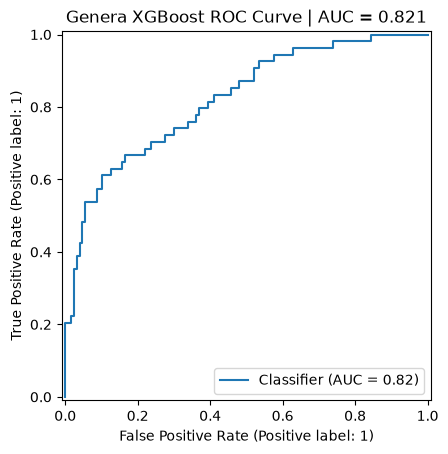

In [26]:
y_genus_pred_proba = cross_val_predict(
    xgb_genus_pipe, X_genus, y_genus, cv=cv,
    method="predict_proba", n_jobs=-1
)[:, 1]

auc_genus = roc_auc_score(y_genus, y_genus_pred_proba)

print("Genera XGBoost ROC-AUC:", round(auc_genus, 3))

RocCurveDisplay.from_predictions(y_genus, y_genus_pred_proba)
plt.title(f"Genera XGBoost ROC Curve | AUC = {auc_genus:.3f}")
plt.show()

In [13]:
plt.savefig("xgboost_genera_roc.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [12]:
model_comparison = pd.DataFrame({
    "Model": ["Species XGBoost", "Genus XGBoost"],
    "Features": [X_var.shape[1], X_genus_var.shape[1]],
    "ROC_AUC": [auc_species, auc_genus]
})

model_comparison

NameError: name 'X_var' is not defined

In [33]:
model_comparison.to_csv(
    "species_vs_genus_xgboost_results.csv",
    index=False
)

In [14]:
from sklearn.model_selection import cross_val_score

genus_auc_scores = cross_val_score(
    xgb_genus_pipe,
    X_genus_var,
    y_genus,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Genera fold AUCs:", np.round(genus_auc_scores, 3))
print("Genera mean ROC-AUC:", round(genus_auc_scores.mean(), 3))
print("Genera SD ROC-AUC:", round(genus_auc_scores.std(), 3))

Genera fold AUCs: [0.872 0.938 0.862 0.862 0.692 0.877 0.969 0.764 0.653 0.708]
Genera mean ROC-AUC: 0.82
Genera SD ROC-AUC: 0.103


# Metabolomics xgboost

In [27]:
mtb = pd.read_csv("data/mtb.tsv", sep="\t")

print("Metabolomics shape:", mtb.shape)
print(mtb.columns[:10])
mtb.head()

Metabolomics shape: (347, 451)
Index(['Sample', 'C00024_Acetyl CoA', 'C01996_Acetylcholine', 'C00147_Adenine',
       'C00212_Adenosine', 'C00054_Adenosine 3',5'-diphosphate',
       'C00224_Adenosine 5'-phosphosulfate', 'C06104_Adipate', 'C03626_ADMA',
       'C00008_ADP'],
      dtype='str')


,Sample,C00024_Acetyl CoA,C01996_Acetylcholine,C00147_Adenine,C00212_Adenosine,"C00054_Adenosine 3',5'-diphosphate",C00224_Adenosine 5'-phosphosulfate,C06104_Adipate,C03626_ADMA,C00008_ADP,...,C00440_5-Methyltetrahydrofolate,C00170_5-Methylthioadenosine,C01879_5-Oxoproline,C02378_6-Aminohexanoate,C06103_6-Hydroxyhexanoate,C01020_6-Hydroxynicotinate,C08434_6-Methylaminopurine,"C02953_7,8-Dihydrobiopterin","C04874_7,8-Dihydroneopterin",C02242_7-Methylguanine
0,10021,102.420732,3.005386,8.117575,25.825384,0.0,0.0,0.000000,113.171491,67.647394,...,147.326466,17.031863,147.104933,0.000000,0.0,0.0,0,3.051459,0.000000,101.795666
1,10023,0.000000,2.817995,13.490150,51.678173,0.0,0.0,203.769908,37.883322,0.000000,...,20.100209,24.435640,75.318162,0.000000,0.0,0.0,0,3.633562,0.000000,85.810880
2,10025,90.176705,1.580793,13.094214,76.001952,0.0,0.0,214.584324,41.823472,40.383801,...,15.993112,25.277564,171.355384,0.000000,0.0,0.0,0,15.663284,0.000000,82.423267
3,10029,0.000000,0.879373,27.859706,42.646169,0.0,0.0,518.799086,9.185715,0.000000,...,0.000000,10.450151,219.793994,12.320705,0.0,0.0,0,0.000000,16.829944,84.976101
4,10031,38.328137,1.296656,17.676669,36.309848,0.0,0.0,255.590336,47.705418,31.734620,...,12.625469,22.669010,107.678076,0.000000,0.0,0.0,0,26.247682,0.000000,80.265689


In [28]:
mtb_data = mtb.merge(metadata, on="Sample", how="inner")

mtb_data = mtb_data[
    mtb_data["Study.Group"].isin(["Healthy", "Stage_III_IV"])
].copy()

mtb_data["Label"] = (
    mtb_data["Study.Group"] == "Stage_III_IV"
).astype(int)

print(mtb_data["Study.Group"].value_counts())
print(mtb_data.shape)

Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64
(181, 466)


In [29]:
mtb_feature_cols = mtb.columns.drop("Sample")

X_mtb = mtb_data[mtb_feature_cols].copy()
y_mtb = mtb_data["Label"].copy()

print("X_mtb shape:", X_mtb.shape)
print("y_mtb counts:")
print(y_mtb.value_counts())

print("Missing values:", X_mtb.isna().sum().sum())

X_mtb shape: (181, 450)
y_mtb counts:
Label
0    127
1     54
Name: count, dtype: int64
Missing values: 0


In [30]:
from sklearn.feature_selection import VarianceThreshold

vt_mtb = VarianceThreshold(threshold=0)

X_mtb_var_array = vt_mtb.fit_transform(X_mtb)

mtb_selected_features = X_mtb.columns[vt_mtb.get_support()]

X_mtb_var = pd.DataFrame(
    X_mtb_var_array,
    columns=mtb_selected_features,
    index=X_mtb.index
)

print("Shape after zero-variance filtering:", X_mtb_var.shape)

Shape after zero-variance filtering: (181, 428)


Metabolomics XGBoost ROC-AUC: 0.751


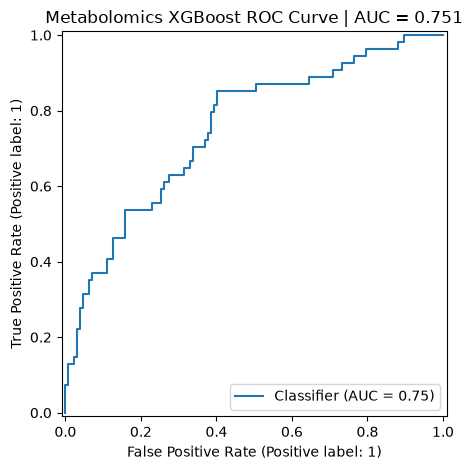

In [32]:
xgb_mtb_pipe = Pipeline([
    ("variance", VarianceThreshold(threshold=0)),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("xgb", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

y_mtb_pred_proba = cross_val_predict(
    xgb_mtb_pipe, X_mtb, y_mtb, cv=cv,
    method="predict_proba", n_jobs=-1
)[:, 1]

auc_mtb = roc_auc_score(y_mtb, y_mtb_pred_proba)

print("Metabolomics XGBoost ROC-AUC:", round(auc_mtb, 3))

RocCurveDisplay.from_predictions(y_mtb, y_mtb_pred_proba)
plt.title(f"Metabolomics XGBoost ROC Curve | AUC = {auc_mtb:.3f}")
plt.tight_layout()
plt.savefig("xgboost_metabolomics_roc.png", dpi=300)
plt.show()

In [33]:
mtb_auc_scores = cross_val_score(
    xgb_mtb_pipe,
    X_mtb_var,
    y_mtb,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Metabolomics fold AUCs:", np.round(mtb_auc_scores, 3))
print("Metabolomics mean ROC-AUC:", round(mtb_auc_scores.mean(), 3))
print("Metabolomics SD ROC-AUC:", round(mtb_auc_scores.std(), 3))

NameError: name 'cross_val_score' is not defined

In [29]:
print(len(y_species_pred_proba))
print(len(y_mtb_pred_proba))

print(X_var.shape)
print(X_mtb_var.shape)

181
181
(181, 13882)
(181, 428)


#Late integration


In [34]:
print((genera_data["Sample"].values == mtb_data["Sample"].values).all())

True


Genera + Metabolomics Late Integration ROC-AUC: 0.836


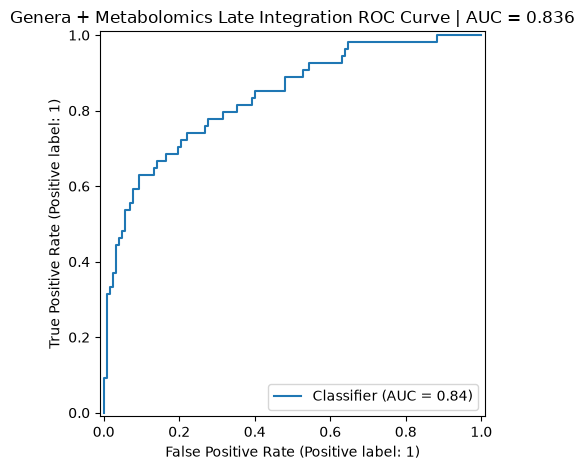

In [35]:
combined_genera_mtb_pred_proba = (
    y_genus_pred_proba + y_mtb_pred_proba
) / 2

auc_combined_genera_mtb = roc_auc_score(
    y_genus,
    combined_genera_mtb_pred_proba
)

print("Genera + Metabolomics Late Integration ROC-AUC:",
      round(auc_combined_genera_mtb, 3))

RocCurveDisplay.from_predictions(
    y_genus,
    combined_genera_mtb_pred_proba
)

plt.title(
    f"Genera + Metabolomics Late Integration ROC Curve | AUC = {auc_combined_genera_mtb:.3f}"
)
plt.tight_layout()
plt.savefig("late_integration_genera_metabolomics_roc.png", dpi=300)
plt.show()

In [37]:
model_comparison = pd.DataFrame({
    "Model": [
        "Species XGBoost",
        "Genera XGBoost",
        "Metabolomics XGBoost",
        "Late Integration"
    ],
    "Features": [
        X_var.shape[1],
        X_genus_var.shape[1],
        X_mtb_var.shape[1],
        X_var.shape[1] + X_mtb_var.shape[1]
    ],
    "ROC_AUC": [
        auc_species,
        auc_genus,
        auc_mtb,
        auc_combined
    ]
})

model_comparison

NameError: name 'X_genus_var' is not defined

SHAP

In [ ]:
# !pip install shap

In [ ]:
# pip install "numpy<=2.4"

Note: you may need to restart the kernel to use updated packages.


: 

In [ ]:
import shap

# Fit final genera model
xgb_genus_pipe.fit(X_genus_var, y_genus)

# Log-transform input exactly like the pipeline
X_genus_log = np.log1p(X_genus_var)

# Optional: sample rows to reduce memory
X_genus_shap = X_genus_log.sample(
    n=min(100, X_genus_log.shape[0]),
    random_state=42
)

explainer = shap.TreeExplainer(xgb_genus_pipe.named_steps["xgb"])
shap_values = explainer.shap_values(X_genus_shap)

shap.summary_plot(
    shap_values,
    X_genus_shap,
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig("genera_xgboost_shap_beeswarm.png", dpi=300)
plt.show()

/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
/tmp/ipykernel_2089407/3075199428.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


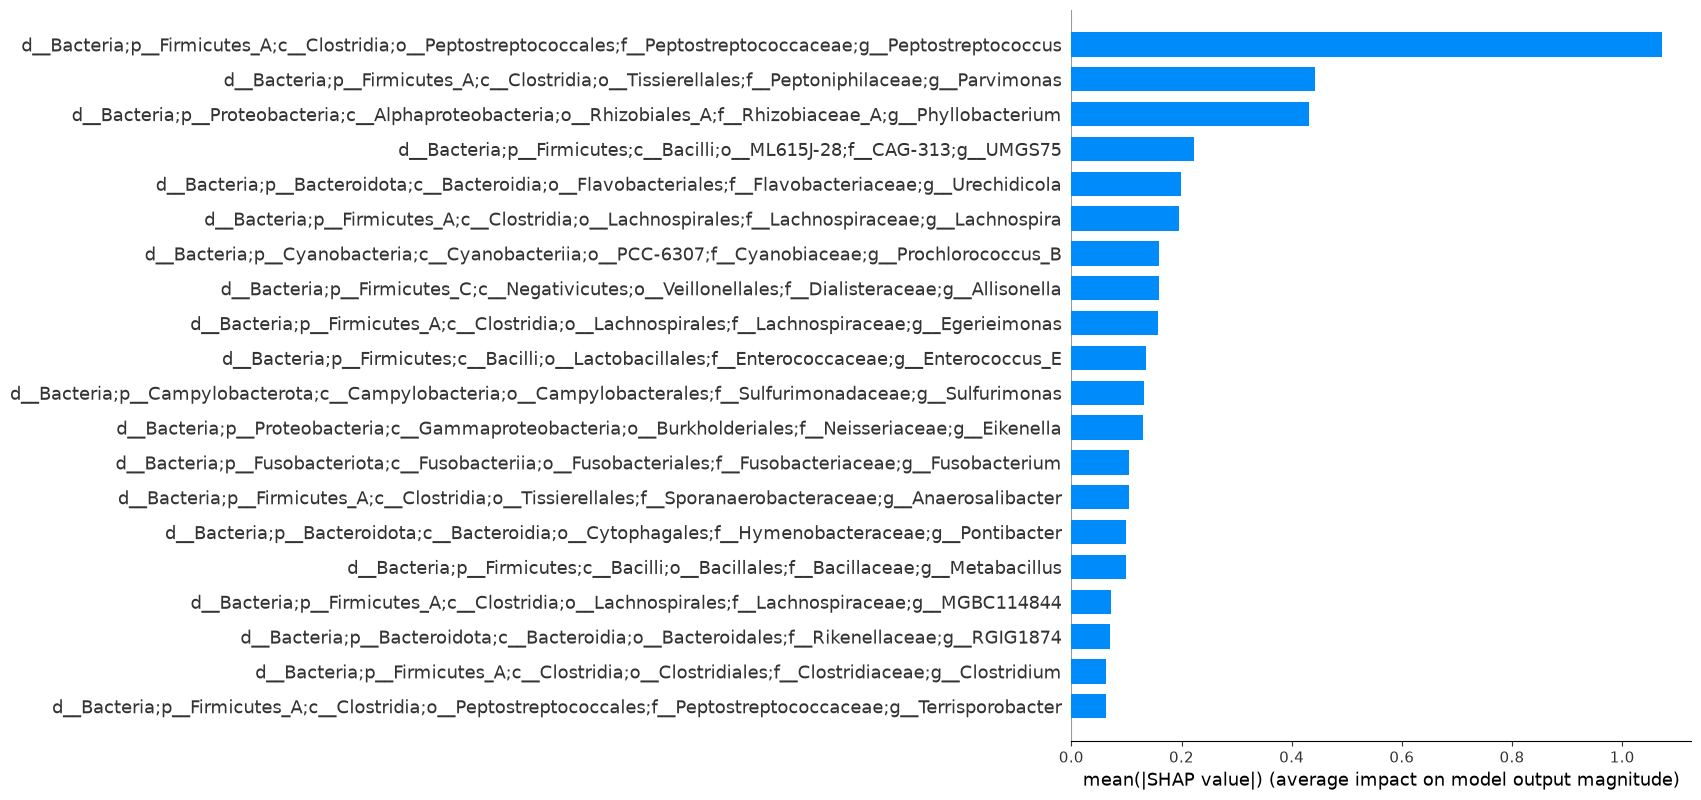

In [28]:
shap.summary_plot(
    shap_values,
    X_genus_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig("genera_xgboost_shap_bar.png", dpi=300)
plt.show()

SHAP analysis identified several bacterial genera that contributed strongly to XGBoost predictions. High abundances of Peptostreptococcus and Parvimonas were associated with positive SHAP values, indicating an increased contribution toward classification as Stage III/IV colorectal cancer. Conversely, lower abundances of these genera shifted predictions toward the Healthy class. The SHAP analysis therefore provides biological interpretability for the machine learning model by identifying taxa with the greatest influence on classification.

In [ ]:
comparison_plot = model_comparison.copy()

comparison_plot.plot(
    x="Model",
    y="ROC_AUC",
    kind="bar",
    legend=False,
    figsize=(7,5)
)

plt.ylabel("ROC-AUC")
plt.ylim(0.5, 1.0)
plt.title("Comparison of XGBoost Models")

plt.tight_layout()
plt.savefig("xgboost_model_comparison.png", dpi=300)
plt.show()